# Trade Route Intelligence

Compare directional market relationships and their product breadth. A route here is an exporter?importer pair in the trade extract.

See the [release guide](../docs/TRADE_INTELLIGENCE_RELEASE.md) for the source and validation workflow.

In [1]:
from pathlib import Path
import sys

from IPython.display import Markdown, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks" / "notebook_support.py").is_file())
sys.path.insert(0, str(root / "notebooks"))
from notebook_support import BLUE, GOLD, TEAL, bar_chart, load_release, top

manifest, data = load_release('route_intelligence')
year = manifest["year"]
display(Markdown(f"**Dataset year:** {year}  |  **Release:** `{manifest['release_id']}`"))


**Dataset year:** 2024  |  **Release:** `ti-3349f6e0cb6dde75fe7d5323af71463748cad3232bc7bcb476c6ff6dcd8cd41b`

## Charts

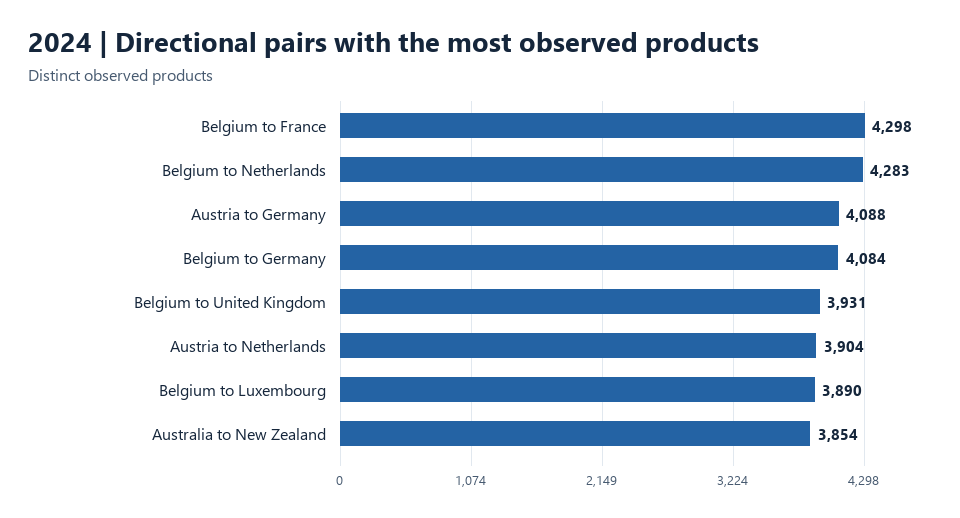

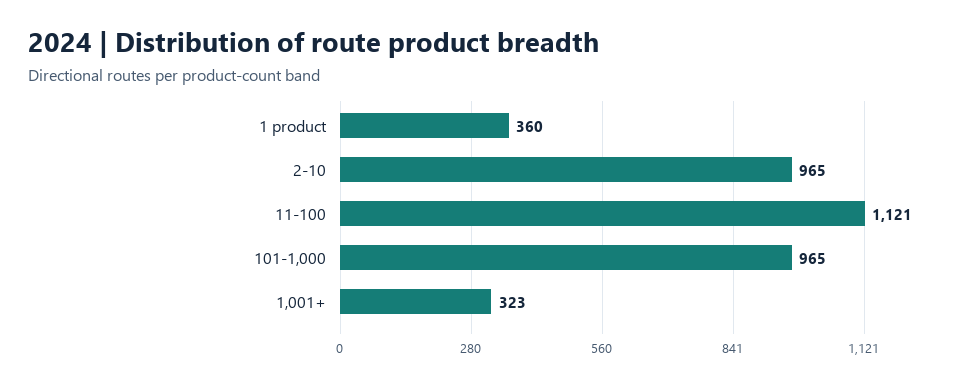

In [2]:
rows = data["records"]
leaders = top(rows, "distinct_products", lambda r: (r["exporter"]["code"], r["importer"]["code"]))
display(bar_chart(f"{year} | Directional pairs with the most observed products", "Distinct observed products",
                  [(f'{r["exporter"]["name"]} to {r["importer"]["name"]}', r["distinct_products"])
                   for r in leaders], BLUE))

bands = [("1 product", 1, 1), ("2-10", 2, 10), ("11-100", 11, 100),
         ("101-1,000", 101, 1000), ("1,001+", 1001, float("inf"))]
distribution = [(name, sum(lo <= r["distinct_products"] <= hi for r in rows))
                for name, lo, hi in bands]
display(bar_chart(f"{year} | Distribution of route product breadth",
                  "Directional routes per product-count band", distribution, TEAL))


## Analysis

In [3]:
assert sum(n for _, n in distribution) == len(rows)
assert all(r["record_count"] == r["distinct_products"] for r in rows)
lead = leaders[0]
reverse = sum(r["reverse_observed"] for r in rows)
short = distribution[0][1] + distribution[1][1]
display(Markdown(f'''
### What the charts show
- **{lead["exporter"]["name"]} ? {lead["importer"]["name"]}** has the widest product coverage in this extract, with **{lead["distinct_products"]:,}** distinct products.
- **{short:,} of {len(rows):,}** directional routes ({short / len(rows):.1%}) have ten or fewer observed products.
- **{reverse:,}** directional routes have an observed reverse direction, forming **{data["metadata"]["reciprocal_pairs"]:,}** reciprocal pairs. A reverse link missing from the extract is unobserved here.
- With one eligible record per year, directional pair and product, route record counts equal distinct product counts. Each product on a route contributes one record, so those records provide no basis for ranking products within the route.
'''))



### What the charts show
- **Belgium ? France** has the widest product coverage in this extract, with **4,298** distinct products.
- **1,325 of 3,734** directional routes (35.5%) have ten or fewer observed products.
- **396** directional routes have an observed reverse direction, forming **198** reciprocal pairs. A reverse link missing from the extract is unobserved here.
- With one eligible record per year, directional pair and product, route record counts equal distinct product counts. Each product on a route contributes one record, so those records provide no basis for ranking products within the route.


### Reading the results

The single-year export reached Excel's worksheet limit and has partial geographic coverage. Record counts measure observed keys in the extract. Currency, trade-value scale, quantity units and HS revision remain unverified. These charts use neither trade values nor quantities. Missing observations provide no evidence of market absence, and the extract cannot establish trends or future demand.
